Nigeria and Global CO₂ Emissions: Trends and Comparisons

Project Overview

This project uses Python to explore historical carbon dioxide emissions, compare Nigeria with selected countries, and examine differences between total emissions and emissions per capita. The analysis covers data inspection, data quality, cleaning, exploratory data analysis, visualisation and interpretation of findings.

Research Questions
1. How have Nigeria's CO₂ emissions changed over time?
2. How does Nigeria compare with selected African countries?
3. How do total emissions compare with emissions per capita?
4. How have emissions changed across the countries included in the analysis?
5. What patterns and limitations can be identified in the dataset?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("owid_co2.csv")

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully.
Number of rows and columns: (50411, 79)


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    50411 non-null  str    
 1   year                                       50411 non-null  int64  
 2   iso_code                                   42480 non-null  str    
 3   population                                 41167 non-null  float64
 4   gdp                                        15251 non-null  float64
 5   cement_co2                                 29173 non-null  float64
 6   cement_co2_per_capita                      25648 non-null  float64
 7   co2                                        29384 non-null  float64
 8   co2_growth_abs                             27216 non-null  float64
 9   co2_growth_prct                            26239 non-null  float64
 10  co2_including_luc                

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values in the first 20 columns:")
display(df.isna().sum().head(20))

Column names:
['country', 'year', 'iso_code', 'population', 'gdp', 'cement_co2', 'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct', 'co2_including_luc', 'co2_including_luc_growth_abs', 'co2_including_luc_growth_prct', 'co2_including_luc_per_capita', 'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy', 'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'coal_co2', 'coal_co2_per_capita', 'consumption_co2', 'consumption_co2_per_capita', 'consumption_co2_per_gdp', 'cumulative_cement_co2', 'cumulative_co2', 'cumulative_co2_including_luc', 'cumulative_coal_co2', 'cumulative_flaring_co2', 'cumulative_gas_co2', 'cumulative_luc_co2', 'cumulative_oil_co2', 'cumulative_other_co2', 'energy_per_capita', 'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita', 'gas_co2', 'gas_co2_per_capita', 'ghg_excluding_lucf_per_capita', 'ghg_per_capita', 'land_use_change_co2', 'land_use_change_co2_per_capita', 'methane', 'methane_per_capita', 'nitrous_oxide', 'nitrous_oxide

country                                  0
year                                     0
iso_code                              7931
population                            9244
gdp                                  35160
cement_co2                           21238
cement_co2_per_capita                24763
co2                                  21027
co2_growth_abs                       23195
co2_growth_prct                      24172
co2_including_luc                    26615
co2_including_luc_growth_abs         26915
co2_including_luc_growth_prct        26915
co2_including_luc_per_capita         26654
co2_including_luc_per_gdp            33621
co2_including_luc_per_unit_energy    40278
co2_per_capita                       23902
co2_per_gdp                          32883
co2_per_unit_energy                  39585
coal_co2                             28486
dtype: int64

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


print("Duplicate rows:", df.duplicated().sum())


main_columns = [
    "country",
    "year",
    "iso_code",
    "population",
    "gdp",
    "co2",
    "co2_per_capita"
]

display(df[main_columns].isna().sum().to_frame("Missing Values"))

Number of rows: 50411
Number of columns: 79
Duplicate rows: 0


,Missing Values
country,0
year,0
iso_code,7931
population,9244
gdp,35160
co2,21027
co2_per_capita,23902


In [6]:
main_columns = [
    "country",
    "year",
    "iso_code",
    "population",
    "gdp",
    "co2",
    "co2_per_capita"
]

missing_summary = df[main_columns].isna().sum()

display(missing_summary)

country               0
year                  0
iso_code           7931
population         9244
gdp               35160
co2               21027
co2_per_capita    23902
dtype: int64

In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Rows: 50411
Columns: 79
Duplicate rows: 0


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Earliest year:", df["year"].min())
print("Latest year:", df["year"].max())

print("\nSelected country names available in the data:")

countries_to_check = [
    "Nigeria", "Ghana", "South Africa",
    "Kenya", "World"
]

display(
    df.loc[
        df["country"].isin(countries_to_check),
        ["country", "year"]
    ]
    .groupby("country")
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        records=("year", "count")
    )
)

Earliest year: 1750
Latest year: 2024

Selected country names available in the data:


,first_year,last_year,records
country,,,
Ghana,1750,2024,275
Kenya,1850,2024,175
Nigeria,1850,2024,175
South Africa,1850,2024,175
World,1750,2024,275


In [9]:
key_columns = [
    "country", "year", "iso_code",
    "population", "gdp", "co2", "co2_per_capita"
]

quality_summary = pd.DataFrame({
    "Missing Values": df[key_columns].isna().sum(),
    "Missing Percentage": (
        df[key_columns].isna().mean() * 100
    ).round(2)
})

display(quality_summary)

,Missing Values,Missing Percentage
country,0,0.00
year,0,0.00
iso_code,7931,15.73
population,9244,18.34
gdp,35160,69.75
co2,21027,41.71
co2_per_capita,23902,47.41


In [10]:
duplicate_country_years = df.duplicated(
    subset=["country", "year"]
).sum()

print(
    "Repeated country-year combinations:",
    duplicate_country_years
)

Repeated country-year combinations: 0


In [11]:
selected_countries = [
    "Nigeria",
    "Ghana",
    "South Africa",
    "Kenya",
    "World"
]

available_countries = df["country"].dropna().unique()

selected_countries = [
    country for country in selected_countries
    if country in available_countries
]

analysis_columns = [
    "country",
    "year",
    "population",
    "gdp",
    "co2",
    "co2_per_capita"
]

analysis_df = df.loc[
    df["country"].isin(selected_countries),
    analysis_columns
].copy()

analysis_df = analysis_df.sort_values(
    ["country", "year"]
).reset_index(drop=True)

print("Countries included:", selected_countries)
print("Analysis rows:", len(analysis_df))

display(analysis_df.head(10))

Countries included: ['Nigeria', 'Ghana', 'South Africa', 'Kenya', 'World']
Analysis rows: 1075


,country,year,population,gdp,co2,co2_per_capita
0,Ghana,1750,2340629.0,NaN,NaN,NaN
1,Ghana,1751,NaN,NaN,NaN,NaN
2,Ghana,1752,NaN,NaN,NaN,NaN
3,Ghana,1753,NaN,NaN,NaN,NaN
4,Ghana,1754,NaN,NaN,NaN,NaN
5,Ghana,1755,NaN,NaN,NaN,NaN
6,Ghana,1756,NaN,NaN,NaN,NaN
7,Ghana,1757,NaN,NaN,NaN,NaN
8,Ghana,1758,NaN,NaN,NaN,NaN
9,Ghana,1759,NaN,NaN,NaN,NaN


In [12]:
analysis_df.info()

display(
    analysis_df.isna().sum().to_frame(
        "Missing Values"
    )
)

<class 'pandas.DataFrame'>
RangeIndex: 1075 entries, 0 to 1074
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         1075 non-null   str    
 1   year            1075 non-null   int64  
 2   population      985 non-null    float64
 3   gdp             314 non-null    float64
 4   co2             676 non-null    float64
 5   co2_per_capita  631 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 57.4 KB


,Missing Values
country,0
year,0
population,90
gdp,761
co2,399
co2_per_capita,444


In [13]:
numeric_columns = [
    "year",
    "population",
    "gdp",
    "co2",
    "co2_per_capita"
]

for column in numeric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column],
        errors="coerce"
    )

print("Data types after validation:")
display(analysis_df.dtypes.to_frame("Data Type"))

Data types after validation:


,Data Type
country,str
year,int64
population,float64
gdp,float64
co2,float64
co2_per_capita,float64


In [14]:
nigeria_df = analysis_df.loc[
    analysis_df["country"] == "Nigeria"
].copy()

nigeria_emissions = nigeria_df.dropna(
    subset=["co2"]
).copy()

print("Nigeria records with available CO₂ data:",
      len(nigeria_emissions))

display(
    nigeria_emissions[
        ["year", "co2", "co2_per_capita", "population"]
    ].tail(10)
)

Nigeria records with available CO₂ data: 110


,year,co2,co2_per_capita,population
615,2015,110.524590,0.579659,190671883.0
616,2016,116.395996,0.595548,195443698.0
617,2017,112.540370,0.561987,200254580.0
618,2018,106.785730,0.521062,204938752.0
619,2019,127.859300,0.610349,209485637.0
620,2020,124.899290,0.583652,213996185.0
621,2021,147.776630,0.676233,218529286.0
622,2022,131.440930,0.589023,223150906.0
623,2023,129.376100,0.567731,227882949.0
624,2024,135.824000,0.583739,232679482.0


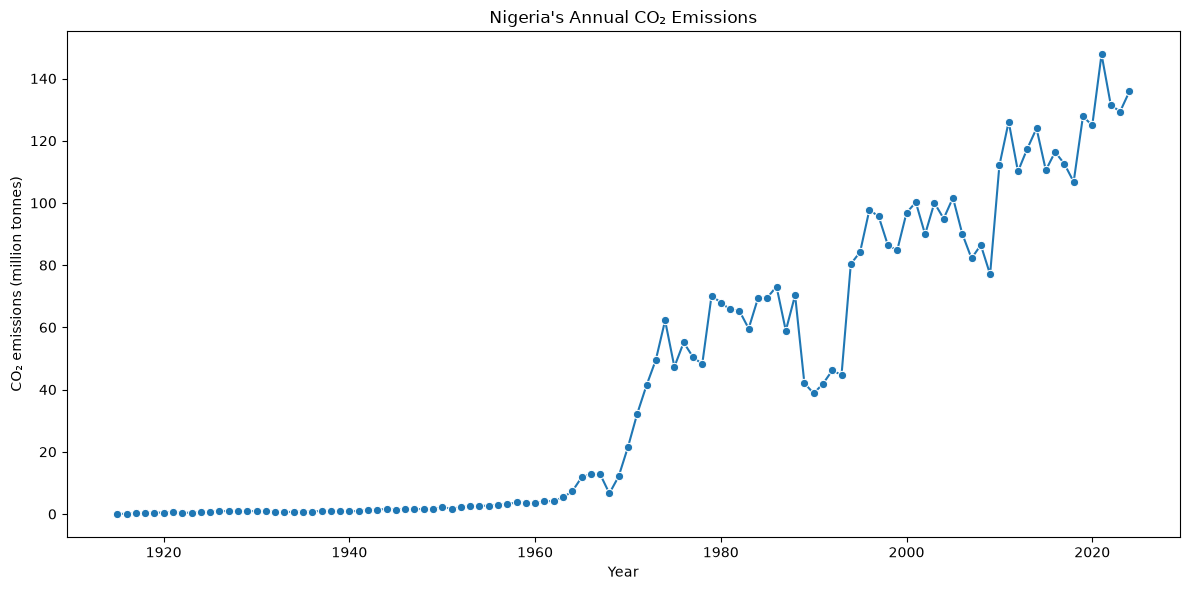

In [15]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=nigeria_emissions,
    x="year",
    y="co2",
    marker="o"
)

plt.title("Nigeria's Annual CO₂ Emissions")
plt.xlabel("Year")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.tight_layout()
plt.show()

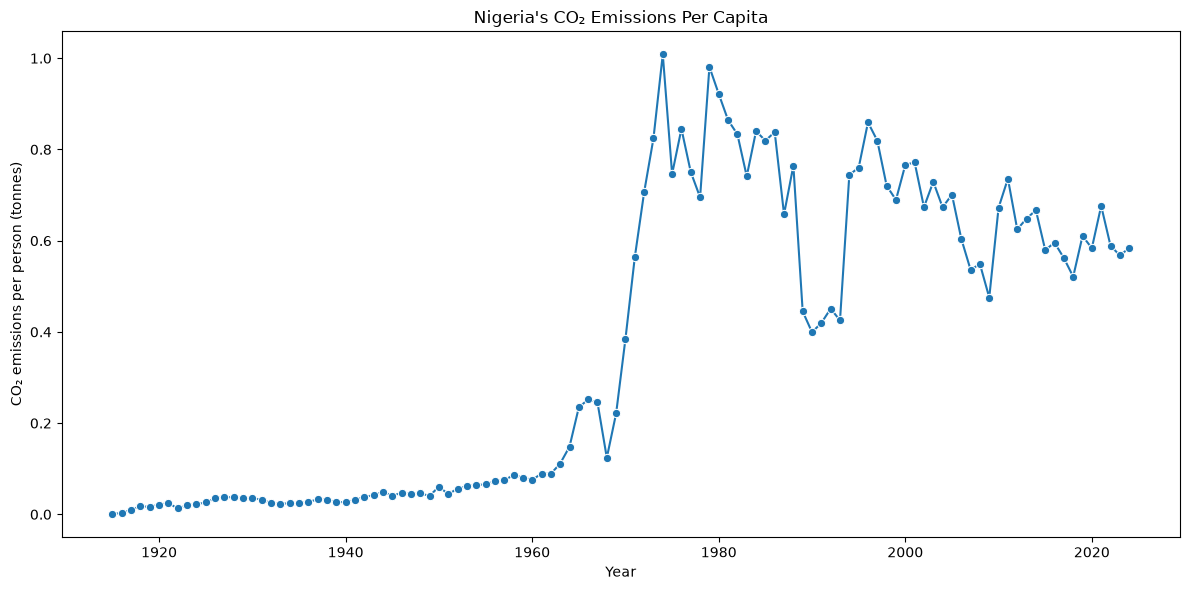

In [16]:
nigeria_per_capita = nigeria_df.dropna(
    subset=["co2_per_capita"]
).copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=nigeria_per_capita,
    x="year",
    y="co2_per_capita",
    marker="o"
)

plt.title("Nigeria's CO₂ Emissions Per Capita")
plt.xlabel("Year")
plt.ylabel("CO₂ emissions per person (tonnes)")
plt.tight_layout()
plt.show()

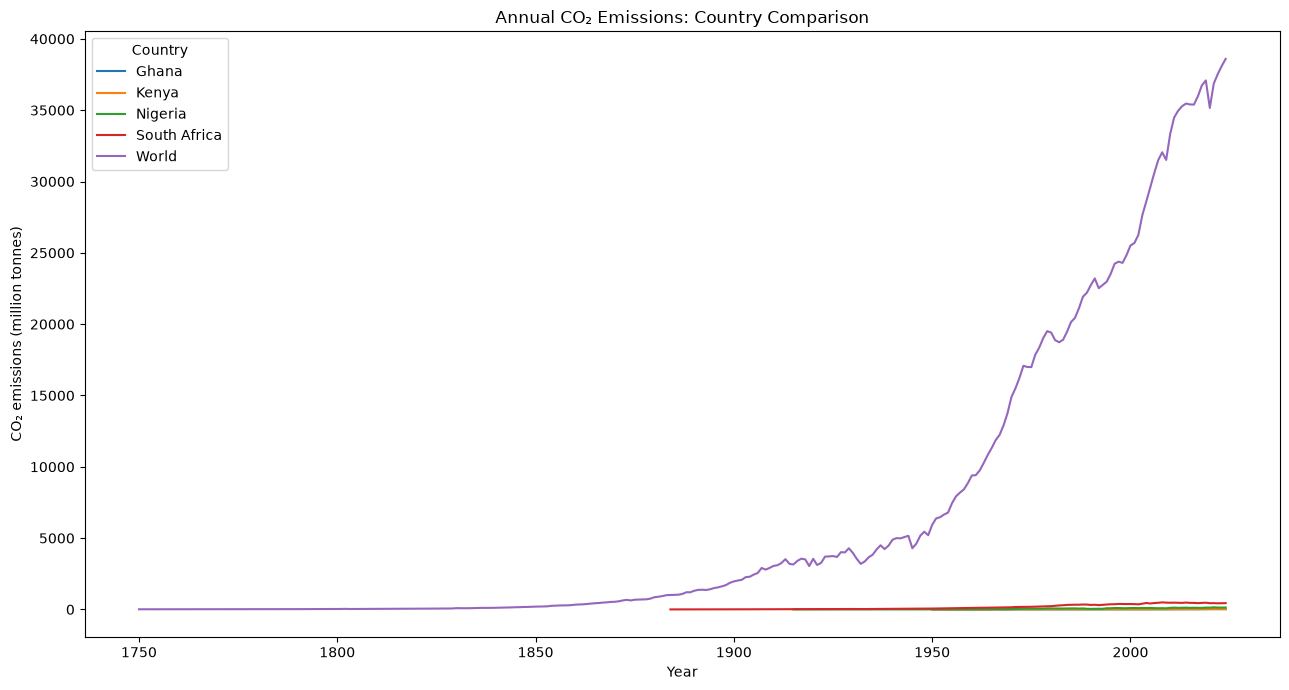

In [17]:
country_emissions = analysis_df.dropna(
    subset=["co2"]
).copy()

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=country_emissions,
    x="year",
    y="co2",
    hue="country"
)

plt.title("Annual CO₂ Emissions: Country Comparison")
plt.xlabel("Year")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

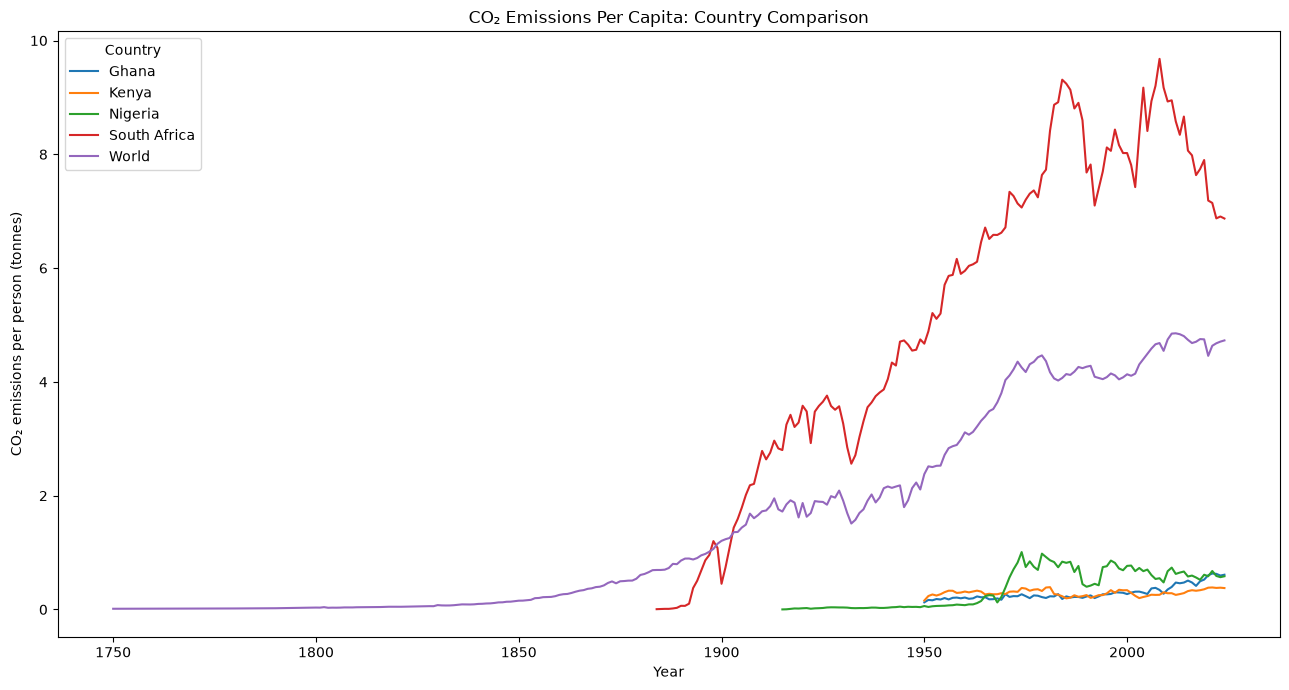

In [18]:
country_per_capita = analysis_df.dropna(
    subset=["co2_per_capita"]
).copy()

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=country_per_capita,
    x="year",
    y="co2_per_capita",
    hue="country"
)

plt.title("CO₂ Emissions Per Capita: Country Comparison")
plt.xlabel("Year")
plt.ylabel("CO₂ emissions per person (tonnes)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

In [19]:
summary_statistics = (
    analysis_df.groupby("country")
    .agg(
        average_co2=("co2", "mean"),
        highest_co2=("co2", "max"),
        average_co2_per_capita=("co2_per_capita", "mean"),
        average_population=("population", "mean"),
        available_co2_years=("co2", "count")
    )
    .round(2)
)

display(summary_statistics)

,average_co2,highest_co2,average_co2_per_capita,average_population,available_co2_years
country,,,,,
Ghana,5.69,21.02,0.29,7.045915e+06,75
Kenya,7.35,21.23,0.29,1.275031e+07,75
Nigeria,42.83,147.78,0.37,5.696632e+07,110
South Africa,161.89,494.67,5.14,1.913087e+07,141
World,6724.09,38598.58,1.83,2.680060e+09,275


In [20]:
change_results = []

for country in selected_countries:
    country_data = (
        analysis_df.loc[
            (analysis_df["country"] == country)
            & analysis_df["co2"].notna(),
            ["year", "co2"]
        ]
        .sort_values("year")
    )

    if len(country_data) < 2:
        continue

    first = country_data.iloc[0]
    last = country_data.iloc[-1]

    change_results.append({
        "country": country,
        "first_year": int(first["year"]),
        "last_year": int(last["year"]),
        "first_co2": first["co2"],
        "last_co2": last["co2"],
        "absolute_change": last["co2"] - first["co2"],
        "percentage_change": (
            (last["co2"] - first["co2"]) / first["co2"] * 100
            if first["co2"] != 0 else np.nan
        )
    })

change_df = pd.DataFrame(change_results).round(2)

display(change_df)

,country,first_year,last_year,first_co2,last_co2,absolute_change,percentage_change
0,Nigeria,1915,2024,0.02,135.82,135.81,741297.38
1,Ghana,1950,2024,0.64,21.02,20.38,3197.36
2,South Africa,1884,2024,0.02,439.83,439.81,2000584.59
3,Kenya,1950,2024,0.91,21.23,20.32,2235.87
4,World,1750,2024,9.31,38598.58,38589.27,414673.71


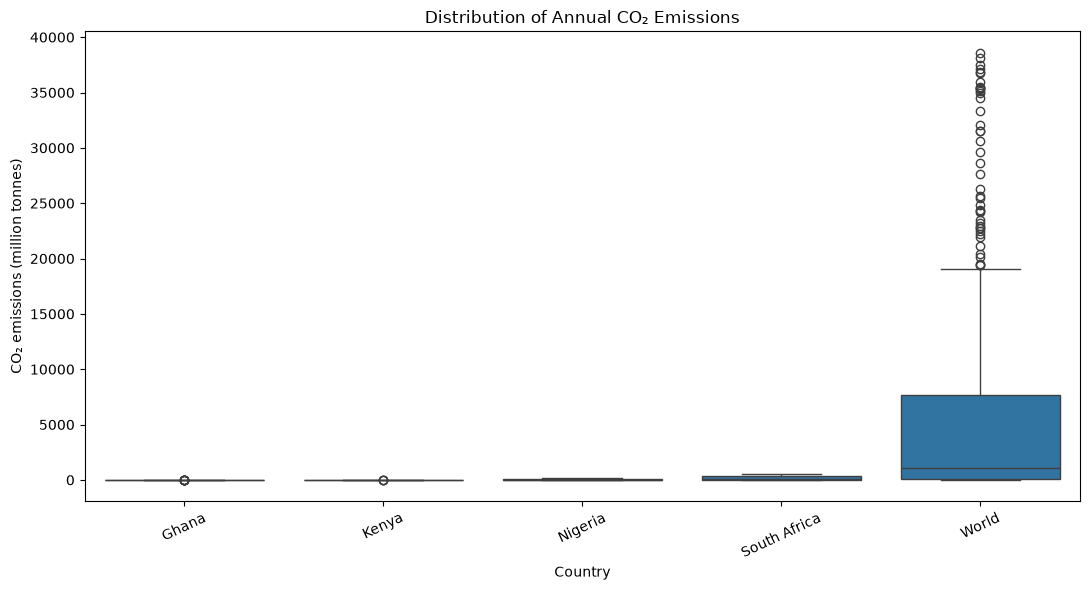

In [21]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=country_emissions,
    x="country",
    y="co2"
)

plt.title("Distribution of Annual CO₂ Emissions")
plt.xlabel("Country")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

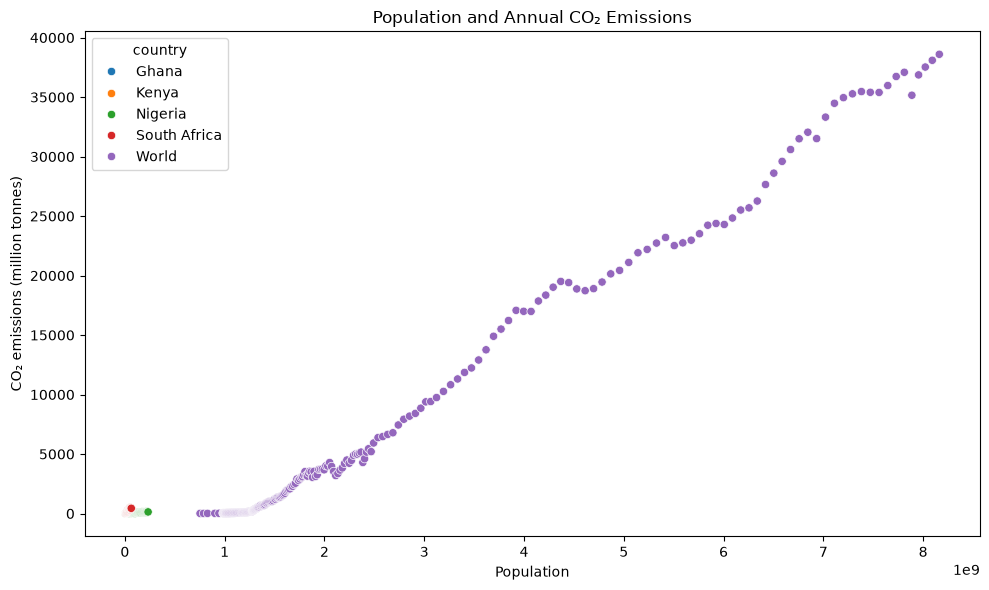

In [22]:
relationship_df = analysis_df.dropna(
    subset=["population", "co2"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=relationship_df,
    x="population",
    y="co2",
    hue="country"
)

plt.title("Population and Annual CO₂ Emissions")
plt.xlabel("Population")
plt.ylabel("CO₂ emissions (million tonnes)")
plt.tight_layout()
plt.show()

In [23]:
correlation = relationship_df[
    ["population", "co2"]
].corr()

display(correlation)

,population,co2
population,1.000000,0.956374
co2,0.956374,1.000000


In [24]:
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

analysis_df.to_csv(
    output_folder / "selected_countries_co2.csv",
    index=False
)

summary_statistics.to_csv(
    output_folder / "country_summary_statistics.csv"
)

change_df.to_csv(
    output_folder / "co2_changes_over_time.csv",
    index=False
)

print("Analysis outputs saved to:", output_folder.resolve())

Analysis outputs saved to: C:\Users\HP\Project_4_C02_Analysis\outputs


Key Findings
Nigeria's CO₂ Emissions Over Time

Nigeria's CO₂ emissions show a long term upward trend, although the pattern is not consistent throughout the entire period. The dataset covers 1915 to 2024. Emissions remained very low during the earlier years, but began increasing more noticeably from around the 1950s, and experienced stronger growth from the 1990s onward. There were also periods of decline, particularly around the early 1980s and between 2016 and 2018. Nigeria's total CO₂ emissions reached a peak of approximately 147.78 million tonnes in 2021 before declining to about 135.82 million tonnes in 2024.

Total Emissions and Emissions Per Capita

The growth in Nigeria's total CO₂ emissions is accompanied by population growth. Between 2015 and 2024, total emissions increased from approximately 110.5 million tonnes to 135.8 million tonnes, while population increased from about 190.7 million to 232.7 million. However, emissions per capita remained relatively low and changed less dramatically than total emissions. It ranged from approximately 0.52 to 0.68 tonnes per person during this period and was about 0.58 tonnes per person in 2024.

The strong association between population and total CO₂ emissions suggests that population growth is an important factor accompanying the increase in Nigeria's total emissions. However, this relationship represents an association rather than proof that population growth directly causes higher emissions.

Comparison with Selected Countries

South Africa recorded the highest average total CO₂ emissions among the selected African countries, averaging approximately 161.89 million tonnes per year. Nigeria ranked second, with an average of about 42.83 million tonnes per year. When emissions are considered on a per-capita basis, the differences become more pronounced. South Africa recorded an average of approximately 5.14 tonnes per person, compared with about 0.37 tonnes per person for Nigeria. Ghana and Kenya recorded averages of approximately 0.29 tonnes per person each. The world average was approximately 1.83 tonnes per person. This means that South Africa was above the world average, while Nigeria, Ghana and Kenya remained below it.

Changes in Total Emissions

Between the beginning and end of each country's available data period, Nigeria's total CO₂ emissions increased by approximately 135.81 million tonnes. Ghana increased by about 20.38 million tonnes, South Africa by about 439.81 million tonnes, and Kenya by approximately 20.32 million tonnes.

Percentage changes should be interpreted cautiously because some countries had very small emission values at the beginning of their available data periods. As a result, percentage growth can appear extremely large even when the absolute increase is relatively modest. Absolute changes therefore provide a more useful comparison in this analysis.

Data Quality and Missing Values

The dataset contained no duplicate rows, and no repeated country-year combinations were identified in the selected analysis. Several important variables contained missing values. CO₂ emissions had approximately 41.71% missing values, CO₂ emissions per capita had approximately 47.41%, and GDP had approximately 69.75%.

GDP was therefore excluded from the main analysis because of its substantial missingness. Missing CO₂-related observations were not replaced with zero. Instead, rows missing the specific variable required for an analysis were excluded only from that analysis. The selected countries also have different periods of available data, so comparisons across countries should be interpreted with this difference in coverage in mind.

Limitations

This analysis focuses on carbon dioxide emissions and does not represent total greenhouse gas emissions. Other greenhouse gases, such as methane and nitrous oxide, are not included. The World aggregate was included as a reference point, but its much larger emission values can dominate charts that use the same scale as individual countries.

The analysis also found a strong correlation between population and total CO₂ emissions. However, correlation does not establish causation, and other factors such as economic activity, energy consumption and industrial development may also influence emissions.

The analysis shows that Nigeria's total CO₂ emissions have increased substantially over the long term, while its per-capita emissions have remained comparatively low. Comparing total emissions with per-capita emissions provides a more balanced understanding of Nigeria's position relative to other countries.